# Figure 3

In [5]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_loo_comparison,
    load_ddm_subj_params,
    load_choicehistorypersubject_betas,
    load_rtlme_switchpersubject_betas,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pingouin as pg
import statsmodels.api as sm

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
STP_DDM_MODEL = "HDDM_Base_Lag1-stp"
DRIFT_DDM_MODEL = "HDDM_Base_Lag1-drift"

### Helper functions

In [6]:
BF_THRESHOLD_HIGH = 3
BF_THRESHOLD_LOW = 1 / 3

BF_COLORS = {
    "evidence_for":     "#017D01",
    "inconclusive":     "#B0B0B0",
    "evidence_against": "#000000",
}


def bf_category(bf10):
    if bf10 > BF_THRESHOLD_HIGH:
        return "evidence_for"
    if bf10 < BF_THRESHOLD_LOW:
        return "evidence_against"
    return "inconclusive"

def spearman_corr_bf(x, y):
    """Spearman r/p (Pearson correlation computed on rank-transformed data,
    which is what Spearman's rho is by definition) plus the resulting JZS
    Bayes Factor (BF10), and an OLS line + 95% CI band fit on the raw
    (non-ranked) points for visual reference."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    rank_x = pd.Series(x).rank().values
    rank_y = pd.Series(y).rank().values

    res = pg.corr(rank_x, rank_y, method="pearson")
    r = float(res["r"].iloc[0])
    pval = float(res["p_val"].iloc[0])
    bf10 = float(res["BF10"].iloc[0])
    category = bf_category(bf10)

    ols_fit = sm.OLS(y, sm.add_constant(x)).fit()
    x_line = np.linspace(x.min(), x.max(), 100)
    pred = ols_fit.get_prediction(sm.add_constant(x_line)).summary_frame(alpha=0.05)

    return {
        "r": r,
        "pval": pval,
        "bf10": bf10,
        "category": category,
        "n": len(x),
        "x_line": x_line,
        "y_line": pred["mean"].values,
        "ci_low": pred["mean_ci_lower"].values,
        "ci_high": pred["mean_ci_upper"].values,
    }


def style_axis(ax, col=None, ylabel=None, xlabel=None, xlabel_col=1):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0 and ylabel:
        ax.set_ylabel(ylabel)
    if col == xlabel_col and xlabel:
        ax.set_xlabel(xlabel)

def format_bf(bf10):
    # one decimal point
    return f"{np.log10(bf10):.1f}"


def format_pval(p):
    if p < 0.001:
        return "<.001"
    if p < 0.01:
        return "<.01"
    if p < 0.05:
        return "<.05"
    return "=n.s."


def plot_spearman_corr(ax, x, y, type):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    result = spearman_corr_bf(x, y)
    color = BF_COLORS[result["category"]]

    ax.axhline(0, color="black", linestyle="--", linewidth=1, zorder=0)
    ax.scatter(x, y, color=color, alpha=0.75, edgecolor="black",
               linewidth=0.5, s=75, zorder=3)
    ax.fill_between(result["x_line"], result["ci_low"], result["ci_high"],
                     color=color, alpha=0.15, zorder=1)
    ax.plot(result["x_line"], result["y_line"], color=color, linewidth=1.5,
            linestyle="-", zorder=4)

    ax.text(0.05, 0.95,
            f"ρ = {result['r']:.2f}, p {format_pval(result['pval'])}\n"
            f"log10(BF10) = {format_bf(result['bf10'])}\nn = {result['n']}",
            transform=ax.transAxes, ha="left", va="top", fontsize = 14,
            color=color, fontweight="bold")

    if type == "choice":
        ax.set_ylim(-2, 2)
    elif type == "rt":
        ax.set_ylim(-0.5, 0.5)

    return result


def _lookup_elpd_diff(loo_df, baseline_model, model_id, column):
    """One (reference_model, target_model) row's diff column from a pairwise
    LOO comparison table (compare_models.py's compare_pair output)."""
    row = loo_df[(loo_df["reference_model"] == baseline_model)
                 & (loo_df["target_model"] == model_id)]
    if len(row) != 1:
        raise ValueError(
            f"Expected exactly one {baseline_model} vs {model_id} row in the "
            f"LOO comparison table, found {len(row)} -- check MODEL_GROUPS in "
            f"compare_models.py."
        )
    return row[column].iloc[0]


def compute_elpd_vs_baseline(dataset, baseline_model, model_order, column="diff_elpd_loo"):
    """LOO elpd diff (all trials shared by each pair) vs. baseline_model,
    read directly off compare_models.py's pairwise comparison table."""
    loo = load_loo_comparison(dataset, group_name="choicehistory")
    return [_lookup_elpd_diff(loo, baseline_model, m, column) for m, _ in model_order]


def compute_elpd_robustness_vs_baseline(dataset, baseline_model, model_order,
                                        column="diff_elpd_reliable"):
    """Same as compute_elpd_vs_baseline, restricted to trials reliable
    (pareto_k <= 0.7) in both models of each pair."""
    loo = load_loo_comparison(dataset, group_name="choicehistory")
    return [_lookup_elpd_diff(loo, baseline_model, m, column) for m, _ in model_order]


ELPD_THRESHOLD = 4

ELPD_COLORS = {
    "improved":  "#017D01",
    "ambiguous": "#8D8D8D",
    "worse":     "#980B0B",
}
ELPD_LABELS = {
    "improved":  "∆elpd > 4",
    "ambiguous": "otherwise",
    "worse":     "∆elpd < -4",
}


def elpd_category(diff):
    if diff > ELPD_THRESHOLD:
        return "improved"
    if diff < -ELPD_THRESHOLD:
        return "worse"
    return "ambiguous"


def plot_elpd_bars(ax, diffs, x_labels, col, show_legend=False):
    x_pos = np.arange(len(diffs))
    colors = [ELPD_COLORS[elpd_category(d)] for d in diffs]
    ax.bar(x_pos, diffs, color=colors, width=0.6, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(-8, 200)
    style_axis(ax, col, ylabel="Improvement over \nbaseline DDM (∆elpd-loo)",
              xlabel="DDM parameter(s) shifted by choice history")

    if show_legend:
        handles = [mpatches.Patch(facecolor=ELPD_COLORS[cat], label=ELPD_LABELS[cat])
                  for cat in ("improved", "worse", "ambiguous")]
        ax.legend(handles=handles, loc="upper left")

### 3x3 figure:
1. LOO improvement
2. Correlation scatterplot
3. Correlation scatterplot


choicehistory_betas
dataset
equalIndifference    47
equalRange           48
sheng2020            71

switch_betas
dataset
equalIndifference    54
equalRange           54
sheng2020            82

Fixed drift rate (v_choice_prev1) vs. switch effect on RT:
  equalIndifference: r = 0.41, p = 0.00184, log10(BF10) = 1.3, n = 54
  equalRange: r = 0.43, p = 0.00105, log10(BF10) = 1.5, n = 54
  sheng2020: r = 0.62, p = 6.46e-10, log10(BF10) = 7.3, n = 82

Starting point (z_choice_prev1) vs. gamble acceptance probability effect:
  equalIndifference: r = 0.43, p = 0.00258, log10(BF10) = 1.2, n = 47
  equalRange: r = 0.08, p = 0.613, log10(BF10) = -0.7, n = 47
  sheng2020: r = 0.42, p = 0.000287, log10(BF10) = 2.0, n = 71


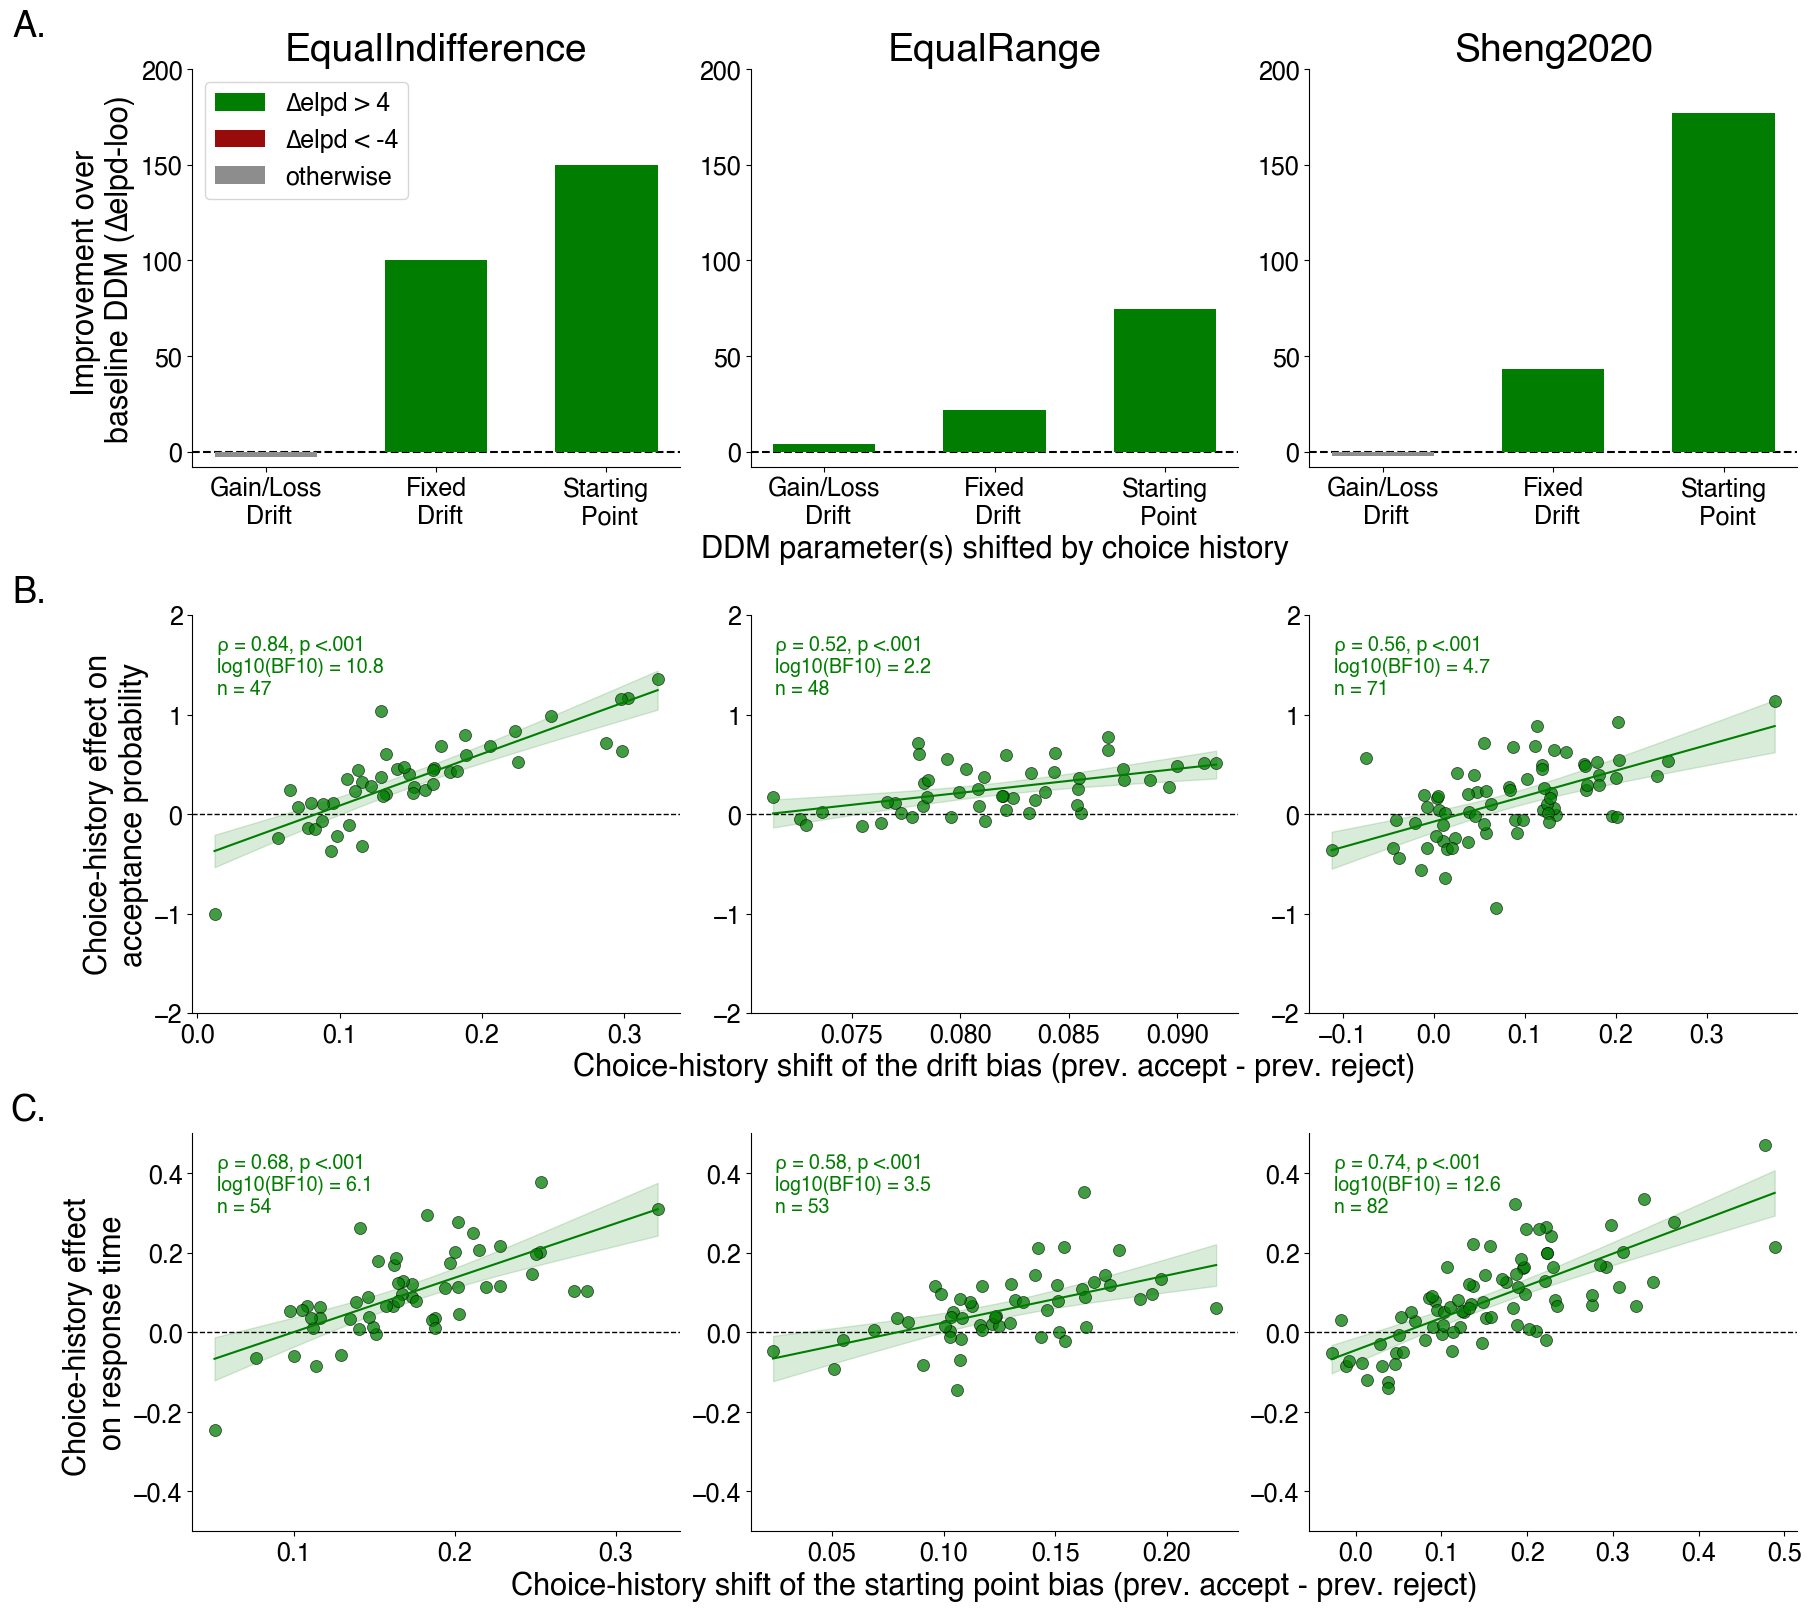

In [7]:
BASELINE_MODEL = "HDDM_Base"

ELPD_MODEL_ORDER = [
    ("HDDM_Base_Lag1-stim",  "Gain/Loss\n Drift"),
    ("HDDM_Base_Lag1-drift", "Fixed\n Drift"),
    ("HDDM_Base_Lag1-stp",   "Starting\n Point"),
]

manual_exclusions_drift = {
    "equalIndifference": [],
    "equalRange": [],
    "sheng2020": []
}

manual_exclusions_stp = {
    "equalIndifference": [],
    "equalRange": [58],
    "sheng2020": []
}

choicehistory_betas = load_choicehistorypersubject_betas()
choicehistory_betas = choicehistory_betas[choicehistory_betas["converged"]]
switch_betas = load_rtlme_switchpersubject_betas()
switch_betas = switch_betas[switch_betas["converged"]]

for name, betas_df in [("choicehistory_betas", choicehistory_betas), ("switch_betas", switch_betas)]:
    print(f"\n{name}")
    print(betas_df.groupby("dataset")["sub"].nunique().to_string())

elpd_vs_baseline = {}
drift_vs_choice = {}
z_vs_switch = {}
drift_vs_switch = {}
z_vs_choice = {}

for ds in DATASETS:
    elpd_vs_baseline[ds] = compute_elpd_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER)

    # v_choice_prev1 (fixed drift shift) and z_choice_prev1 (starting-point
    # shift) come from their own single-mechanism models
    stp_params = (load_ddm_subj_params(STP_DDM_MODEL, ds)
                 .pivot(index="sub", columns="param_name", values="param_value"))
    drift_params = (load_ddm_subj_params(DRIFT_DDM_MODEL, ds)
                    .pivot(index="sub", columns="param_name", values="param_value"))

    beh_ds = (choicehistory_betas[choicehistory_betas["dataset"] == ds]
              .set_index("sub")["choice_prev1_effect"])
    switch_ds = (switch_betas[switch_betas["dataset"] == ds]
                 .set_index("sub")["switch_effect"])

    drift_vs_choice[ds] = pd.concat(
        [drift_params["v_choice_prev1"].rename("v_choice_prev1"), beh_ds.rename("choice_prev1_effect")],
        axis=1, join="inner",
    ).drop(index=manual_exclusions_drift[ds], errors="ignore")
    z_vs_switch[ds] = pd.concat(
        [stp_params["z_choice_prev1"].rename("z_choice_prev1"), switch_ds.rename("switch_effect")],
        axis=1, join="inner",
    ).drop(index=manual_exclusions_stp[ds], errors="ignore")

    # Cross-pairings (not plotted): fixed drift rate vs. the RT switch
    # effect, and the starting point vs. gamble acceptance probability.
    drift_vs_switch[ds] = pd.concat(
        [drift_params["v_choice_prev1"].rename("v_choice_prev1"), switch_ds.rename("switch_effect")],
        axis=1, join="inner",
    ).drop(index=manual_exclusions_drift[ds], errors="ignore")
    z_vs_choice[ds] = pd.concat(
        [stp_params["z_choice_prev1"].rename("z_choice_prev1"), beh_ds.rename("choice_prev1_effect")],
        axis=1, join="inner",
    ).drop(index=manual_exclusions_stp[ds], errors="ignore")

print("\nFixed drift rate (v_choice_prev1) vs. switch effect on RT:")
for ds in DATASETS:
    merged = drift_vs_switch[ds]
    result = spearman_corr_bf(merged["v_choice_prev1"].values, merged["switch_effect"].values)
    print(f"  {ds}: r = {result['r']:.2f}, p = {result['pval']:.3g}, "
         f"log10(BF10) = {format_bf(result['bf10'])}, n = {result['n']}")

print("\nStarting point (z_choice_prev1) vs. gamble acceptance probability effect:")
for ds in DATASETS:
    merged = z_vs_choice[ds]
    result = spearman_corr_bf(merged["z_choice_prev1"].values, merged["choice_prev1_effect"].values)
    print(f"  {ds}: r = {result['r']:.2f}, p = {result['pval']:.3g}, "
         f"log10(BF10) = {format_bf(result['bf10'])}, n = {result['n']}")

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 16), layout="constrained")
elpd_labels = [label for _, label in ELPD_MODEL_ORDER]

for col, ds in enumerate(DATASETS):
    plot_elpd_bars(axes[0, col], elpd_vs_baseline[ds], elpd_labels, col, show_legend=(col == 0))
    axes[0, col].set_title(DATASET_LABELS.get(ds, ds))

    merged = drift_vs_choice[ds]
    plot_spearman_corr(axes[1, col], merged["v_choice_prev1"].values, merged["choice_prev1_effect"].values, type = "choice")
    style_axis(axes[1, col], col,
              ylabel="Choice-history effect on\nacceptance probability",
              xlabel="Choice-history shift of the drift bias (prev. accept - prev. reject)")

    merged = z_vs_switch[ds]
    plot_spearman_corr(axes[2, col], merged["z_choice_prev1"].values, merged["switch_effect"].values, type = "rt")
    style_axis(axes[2, col], col,
              ylabel="Choice-history effect \non response time",
              xlabel="Choice-history shift of the starting point bias (prev. accept - prev. reject)")

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
for row, label in enumerate(["A.", "B.", "C."]):
    y = 1.15 if row == 0 else 1.1
    axes[row, 0].text(-0.3, y, label, transform=axes[row, 0].transAxes,
                      fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure3.svg", dpi=300, bbox_inches="tight")
plt.show()

### Robustness check
Per dataset: ∆elpd (baseline vs. model, from Row A, `diff_elpd_loo` — all trials shared by the pair) next to the PSIS-LOO robustness-check ∆elpd (same comparison restricted to trials reliable in both models, `diff_elpd_reliable`).

In [8]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-stim",  "Gain/Loss\n Drift (1)"),
    ("HDDM_Base_Lag1-drift", "Fixed\n Drift (2)"),
    ("HDDM_Base_Lag1-stp",   "Starting\n Point (3)"),
    ("HDDM_Base_Lag1-stpdrift",  "(2) + (3)"),
    ("HDDM_Base_Lag1-full", "(1) + (2) + (3)")
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, BASELINE_MODEL, ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
                model  delta_elpd  delta_elpd_robust
Gain/Loss\n Drift (1)   -2.568278          -2.434569
    Fixed\n Drift (2)   99.967312         101.303345
 Starting\n Point (3)  149.601843         124.365526
            (2) + (3)  159.014611         140.857536
      (1) + (2) + (3)  155.994953         138.064462

equalRange
                model  delta_elpd  delta_elpd_robust
Gain/Loss\n Drift (1)    4.167093           3.778568
    Fixed\n Drift (2)   21.846329          21.185540
 Starting\n Point (3)   74.754937          63.119092
            (2) + (3)   72.929905          61.326641
      (1) + (2) + (3)   76.992614          64.484561

sheng2020
                model  delta_elpd  delta_elpd_robust
Gain/Loss\n Drift (1)   -2.509093          -2.481795
    Fixed\n Drift (2)   43.006567          44.873144
 Starting\n Point (3)  177.134792         155.810470
            (2) + (3)  192.344726         166.127592
      (1) + (2) + (3)  190.252524         163.676286


In [9]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-stpdrift",  "stpdrift"),
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, "HDDM_Base_Lag1-stp", ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, "HDDM_Base_Lag1-stp", ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
   model  delta_elpd  delta_elpd_robust
stpdrift    9.412768          15.340358

equalRange
   model  delta_elpd  delta_elpd_robust
stpdrift   -1.825031          -2.843383

sheng2020
   model  delta_elpd  delta_elpd_robust
stpdrift   15.209934          12.968819


In [10]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-full",  "full"),
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, "HDDM_Base_Lag1-stpdrift", ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, "HDDM_Base_Lag1-stpdrift", ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
model  delta_elpd  delta_elpd_robust
 full   -3.019658          -2.612701

equalRange
model  delta_elpd  delta_elpd_robust
 full    4.062709           4.100804

sheng2020
model  delta_elpd  delta_elpd_robust
 full   -2.092202          -1.959026


### Bootstrap: starting-point vs. drift correlation with choice/RT effects
Percentile bootstrap (resampling subjects with replacement, `R = 5000`) of the difference in Spearman correlation between the starting-point (`z_choice_prev1`) and drift (`v_choice_prev1`) choice-history shifts, with (1) the choice-history effect on acceptance probability (`choice_prev1_effect`), and (2) the choice-history effect on switching response time (`switch_effect`).

In [11]:
def spearman_r(x, y):
    return pd.Series(np.asarray(x, dtype=float)).rank().corr(
        pd.Series(np.asarray(y, dtype=float)).rank()
    )


def bootstrap_corr_diff(df, col_a, col_b, col_outcome, R=10000, seed=0):
    """Percentile bootstrap (resampling subjects with replacement, R
    replicates) of the difference in Spearman correlation with
    `col_outcome`: corr(col_a, outcome) - corr(col_b, outcome)."""
    rng = np.random.default_rng(seed)
    n = len(df)
    a = df[col_a].to_numpy()
    b = df[col_b].to_numpy()
    y = df[col_outcome].to_numpy()

    def diff_fun(idx):
        return spearman_r(a[idx], y[idx]) - spearman_r(b[idx], y[idx])

    observed = diff_fun(np.arange(n))
    boot_diffs = np.array([
        diff_fun(rng.integers(0, n, size=n)) for _ in range(R)
    ])
    ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])
    return {"observed": observed, "ci_low": ci_low, "ci_high": ci_high, "n": n}


# z_choice_prev1 and v_choice_prev1 joined with each outcome, using the
# subject sets (and manual exclusions) already applied when building
# z_vs_choice/drift_vs_choice and z_vs_switch/drift_vs_switch above.
choice_triple = {}
switch_triple = {}
for ds in DATASETS:
    choice_triple[ds] = pd.concat(
        [drift_vs_choice[ds]["v_choice_prev1"],
         z_vs_choice[ds]["z_choice_prev1"],
         drift_vs_choice[ds]["choice_prev1_effect"]],
        axis=1, join="inner",
    )
    switch_triple[ds] = pd.concat(
        [drift_vs_switch[ds]["v_choice_prev1"],
         z_vs_switch[ds]["z_choice_prev1"],
         drift_vs_switch[ds]["switch_effect"]],
        axis=1, join="inner",
    )

print("diff = corr(z_choice_prev1, choice_prev1_effect) - corr(v_choice_prev1, choice_prev1_effect)")
for ds in DATASETS:
    res = bootstrap_corr_diff(choice_triple[ds], "z_choice_prev1", "v_choice_prev1", "choice_prev1_effect")
    print(f"  {ds}: diff = {res['observed']:.3f}, 95% CI [{res['ci_low']:.3f}, {res['ci_high']:.3f}], n = {res['n']}")

print("\ndiff = corr(z_choice_prev1, switch_effect) - corr(v_choice_prev1, switch_effect)")
for ds in DATASETS:
    res = bootstrap_corr_diff(switch_triple[ds], "z_choice_prev1", "v_choice_prev1", "switch_effect")
    print(f"  {ds}: diff = {res['observed']:.3f}, 95% CI [{res['ci_low']:.3f}, {res['ci_high']:.3f}], n = {res['n']}")

diff = corr(z_choice_prev1, choice_prev1_effect) - corr(v_choice_prev1, choice_prev1_effect)
  equalIndifference: diff = -0.413, 95% CI [-0.615, -0.235], n = 47
  equalRange: diff = -0.414, 95% CI [-0.622, -0.205], n = 47
  sheng2020: diff = -0.143, 95% CI [-0.275, -0.007], n = 71

diff = corr(z_choice_prev1, switch_effect) - corr(v_choice_prev1, switch_effect)
  equalIndifference: diff = 0.270, 95% CI [0.095, 0.459], n = 54
  equalRange: diff = 0.145, 95% CI [-0.022, 0.321], n = 53
  sheng2020: diff = 0.124, 95% CI [0.045, 0.208], n = 82
